# Lab 03 — 01. Exploratory Data Analysis (EDA)

Notebook thực hiện phân tích khám phá dữ liệu (EDA) chuẩn 6 bước theo [`docs/eda.md`](../../../docs/eda.md) trên bộ dữ liệu Rotten Tomatoes Movie Reviews (Cornell). Hỗ trợ chế độ kép: `MODE="view"` để đọc nhanh các artifact đã được xác thực, và `MODE="prepare"` để chạy mới.

## Bảng Lộ Trình Triển Khai Thực Tế (Pipeline Execution Roadmap)

| Bước | Giai đoạn (Phase) | Nội dung chi tiết (Core Description) | Module triển khai / Hàm thực thi | Sản phẩm đầu ra (Output / Artifact) |
| :---: | :--- | :--- | :--- | :--- |
| **1** | **Setup & Khởi tạo phiên** | Khởi tạo NotebookSession, thiết lập cấu hình đường dẫn và kiểm tra tính toàn vẹn môi trường. | [src/notebook_runtime.py](../src/notebook_runtime.py): `NotebookSession` | Instance `session`, biến `MODE`, đường dẫn artifacts |
| **2** | **Bước 1: Tổng quan dữ liệu & Schema** | Xác định kích thước 3 tập dữ liệu (train: 8.530, val: 1.066, test: 1.066), kiểu chuỗi text và nhãn nhị phân. Xem trước các mẫu văn bản thô. | [src/data_preparation.py](../src/data_preparation.py): `export_data_review`<br>[src/datasets/loader.py](../src/datasets/loader.py): `load_data` | `data_preview.json`, bảng hiển thị `train_examples.png` |
| **3** | **Bước 2: Thống kê tổng hợp (Summary Stats)** | Tính toán 5-number summary (Min, Q1, Median, Q3, Max), Mean và Standard Deviation cho số từ (words), số ký tự (chars) và số tokens (WordPiece). | [src/data_preparation.py](../src/data_preparation.py): `compute_summary_statistics` | `preprocessing_statistics.json` |
| **4** | **Bước 3: Phân tích đơn biến & Phân phối** | Khảo sát phân bố độ dài câu, hình dạng đồ thị và kiểm tra độ cân bằng nhãn mục tiêu (Class Distribution 50/50 hoàn hảo). | [src/data_preparation.py](../src/data_preparation.py): `plot_lengths` | `class_distribution.png`, `token_length_distribution.png` |
| **5** | **Bước 4: Phân tích song biến & Outliers** | Phân tích quan hệ Số - Phân loại (độ dài theo nhãn sentiment). Dùng khoảng IQR phát hiện giá trị ngoại lệ và vẽ Boxplot so sánh phân bố giữa nhãn 0 và 1. | [src/data_preparation.py](../src/data_preparation.py): `export_data_review` | `lengths_boxplot.png`, `lengths_by_class.png` |
| **6** | **Bước 5: Dữ liệu khuyết, trùng lặp & Leakage** | Kiểm toán toàn diện giá trị missing, chuỗi rỗng/khoảng trắng, trùng lặp văn bản và rò rỉ dữ liệu chéo giữa các tập chia (cross-split overlap). | [src/data_preparation.py](../src/data_preparation.py): `export_data_review` | `data_quality.json`, `data_quality.png` |
| **7** | **Bước 6: Đánh giá chất lượng & Handoff** | Tổng kết mức độ sạch, tính nhất quán của bộ dữ liệu và xác lập cam kết hợp đồng dữ liệu sẵn sàng chuyển giao cho Feature Engineering. | [src/workflow.py](../src/workflow.py) | Handoff table, `data_quality.png` |

## 1. Setup và khởi tạo phiên làm việc

In [1]:
from pathlib import Path
import subprocess, sys, json
MODE = "view"
DEVICE = "cpu"
REPO_URL = "https://github.com/lacthui06/Lab-DL.git"
REPO_REF = "lab03"
start = Path.cwd().resolve()
REPO = next((p for p in (start,*start.parents) if (p/"labs/lab03/config/frozen_trial.json").is_file()), None)
if REPO is None and Path("/kaggle/working").is_dir():
    REPO = Path("/kaggle/working/Lab-DL")
    if not REPO.exists():
        subprocess.run(["git","clone","--branch",REPO_REF,"--single-branch",REPO_URL,str(REPO)],check=True)
assert REPO is not None, "Mở notebook trong repository hoặc trên Kaggle."
sys.path.insert(0,str(REPO))
from labs.lab03.src.notebook_runtime import NotebookSession
session = NotebookSession(REPO, MODE, DEVICE)
session.setup()
from IPython.display import display


MODE=view: đọc artifacts đã lưu; không cài/tải model, không training.


## 2. Bước 1: Tổng quan dữ liệu & Kiểu dữ liệu (Data Overview & Schema)

Kích thước các tập dữ liệu chính thức:
  - train: 8,530 mẫu
  - validation: 1,066 mẫu
  - test: 1,066 mẫu


**train_examples.png**

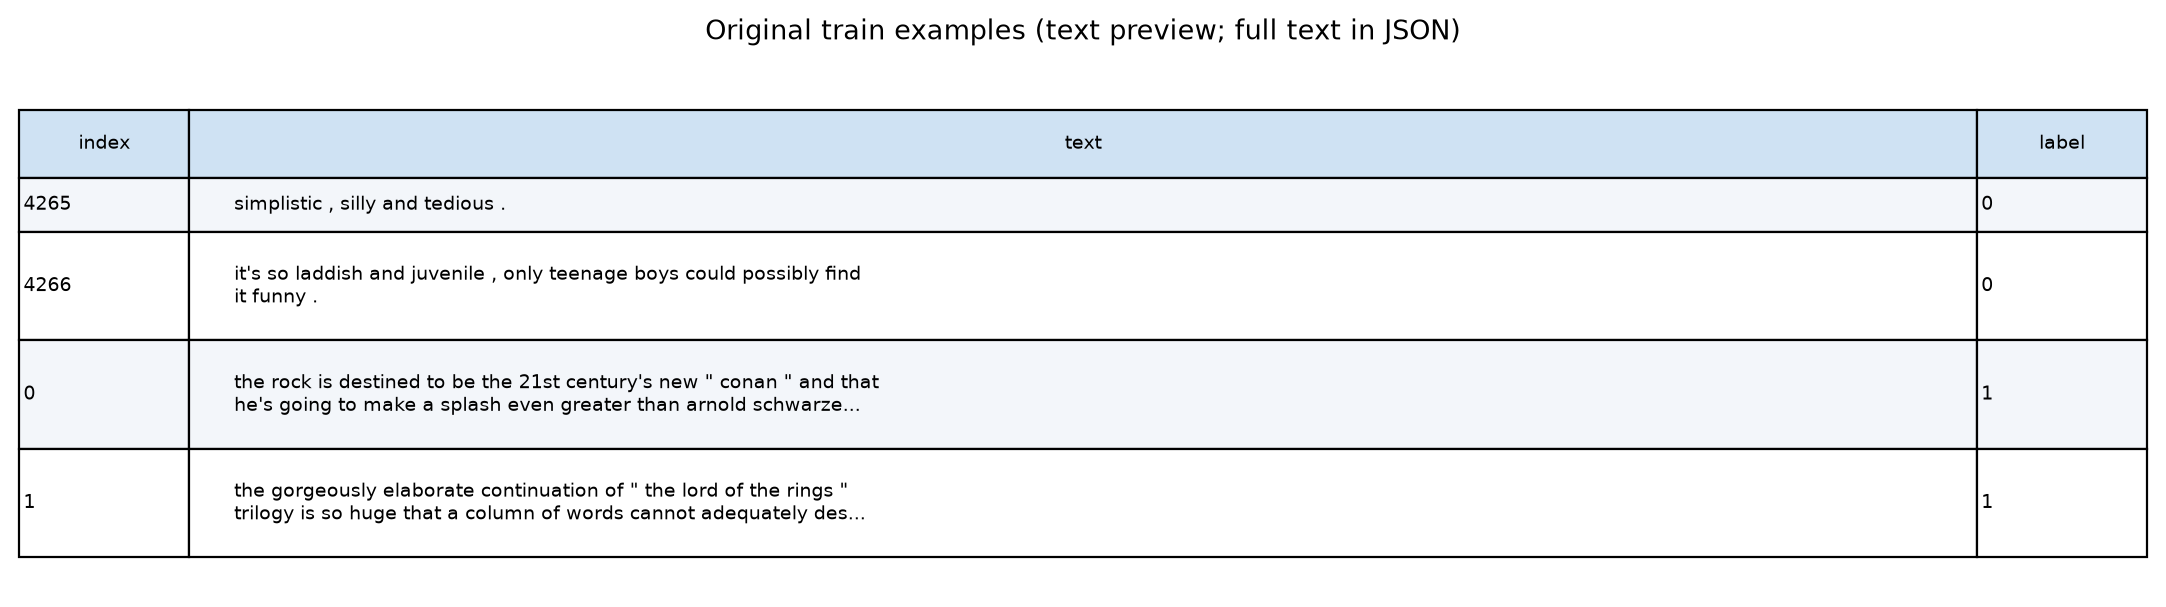

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/train_examples.png')]

In [2]:
session.prepare()
preview = session.read(session.paths["data"] / "data_preview.json")
print("Kích thước các tập dữ liệu chính thức:")
for split, size in preview["split_sizes"].items():
    print(f"  - {split}: {size:,} mẫu")

session.show("data", ["train_examples.png"])

## 3. Bước 2: Thống kê tổng hợp (Summary Statistics & 5-Number Summary)

In [3]:
import pandas as pd
from IPython.display import display

prep_stats = session.read(session.paths["data"] / "preprocessing_statistics.json")
summary_dict = prep_stats.get("summary_statistics", {})

if summary_dict:
    df_summary = pd.DataFrame(summary_dict).T
    cols_order = ["count", "mean", "std", "min", "q1", "median", "q3", "max", "iqr", "outlier_count", "outlier_fraction"]
    display(df_summary[[c for c in cols_order if c in df_summary.columns]])
else:
    display(prep_stats.get("token_quantiles", {}))

,count,mean,std,min,q1,median,q3,max,iqr,outlier_count,outlier_fraction
words,8530.0,20.992849,9.370544,1.0,14.0,20.0,27.0,59.0,13.0,51.0,0.005979
tokens,8530.0,27.368347,11.268360,3.0,19.0,27.0,35.0,78.0,16.0,37.0,0.004338
chars,8530.0,113.971630,51.049239,4.0,76.0,111.0,149.0,267.0,73.0,6.0,0.000703


## 4. Bước 3: Phân tích đơn biến & Phân phối (Univariate Analysis)

**class_distribution.png**

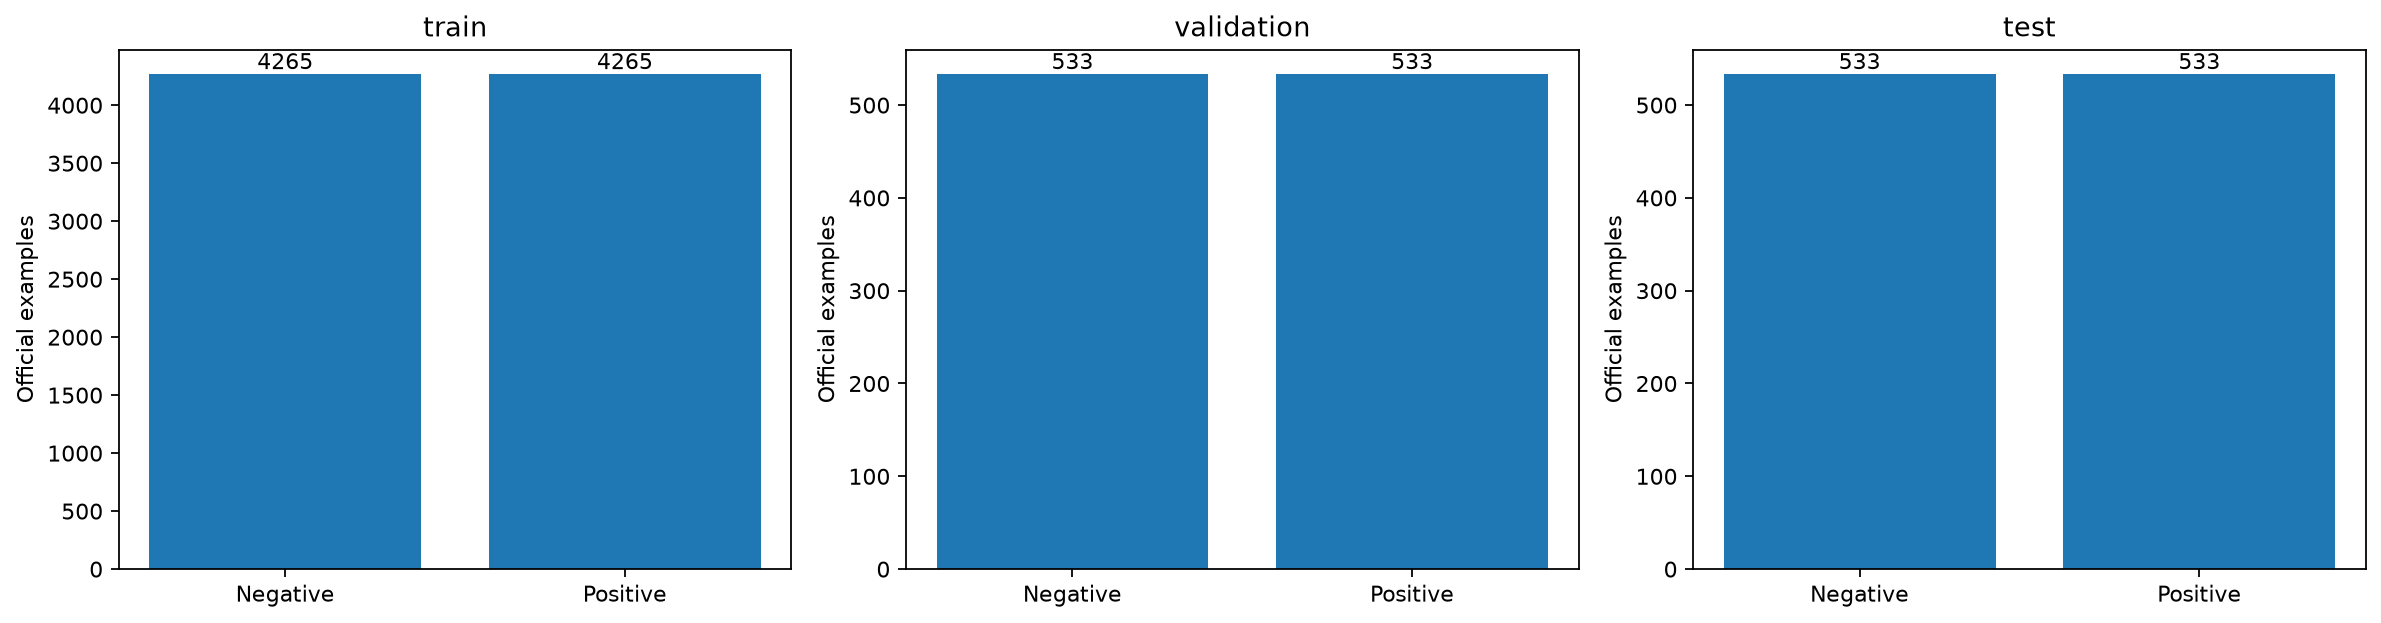

**token_length_distribution.png**

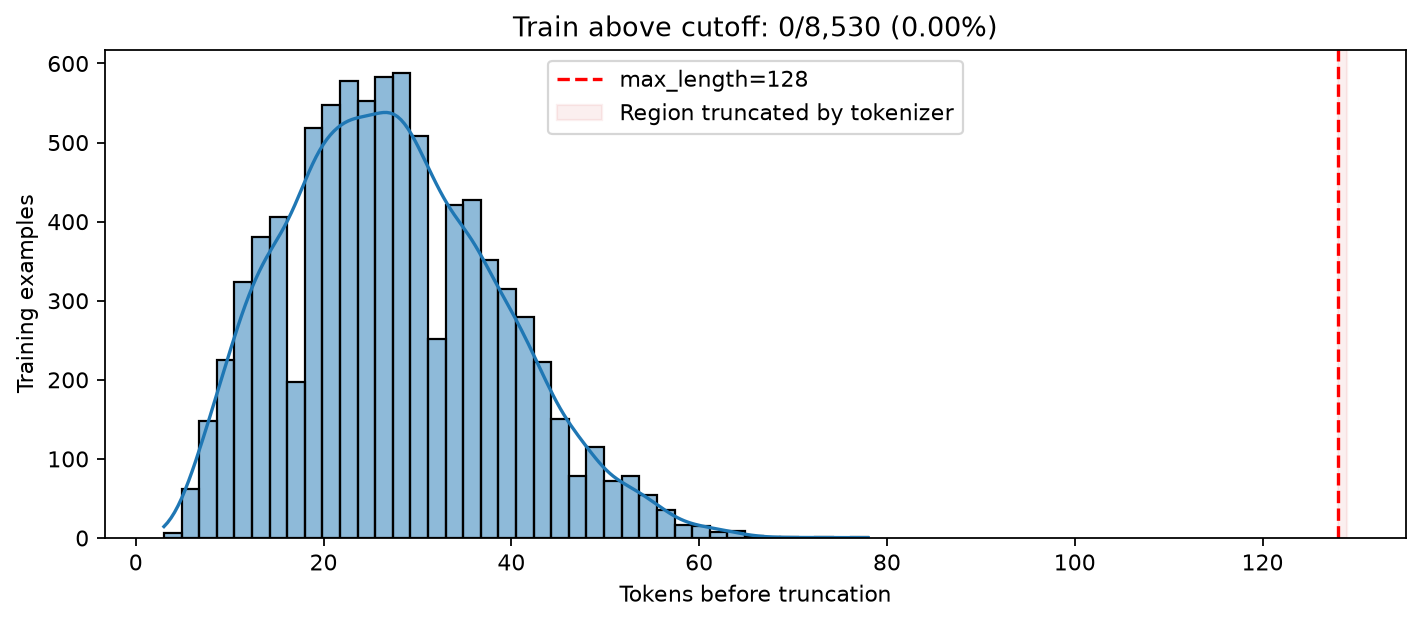

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/class_distribution.png'),
 WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/token_length_distribution.png')]

In [4]:
session.show("data", ["class_distribution.png", "token_length_distribution.png"])

## 5. Bước 4: Phân tích song biến & Dò ngoại lệ IQR (Bivariate & Outlier Analysis)

**lengths_boxplot.png**

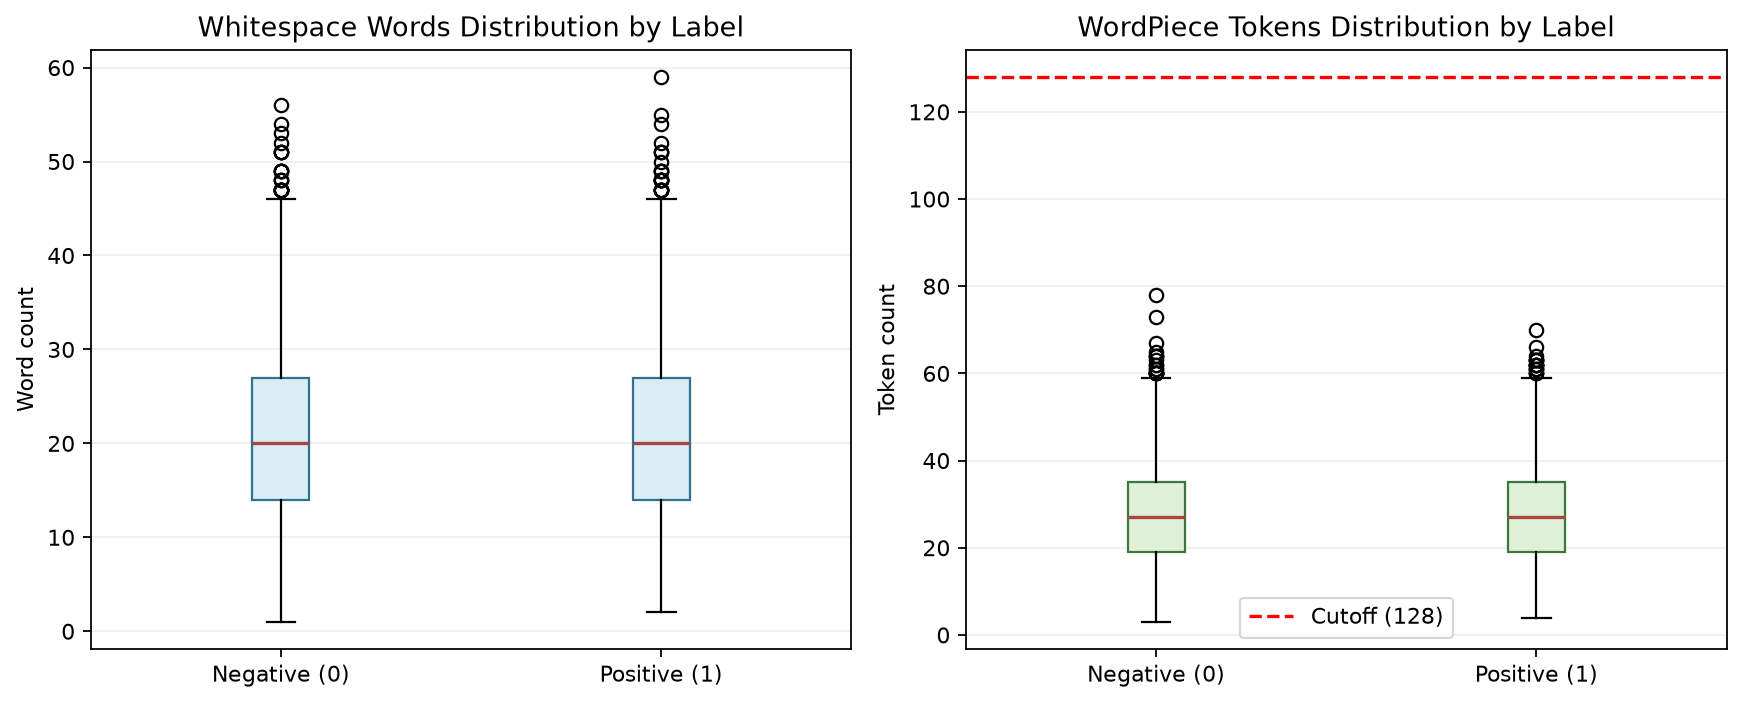

**lengths_by_class.png**

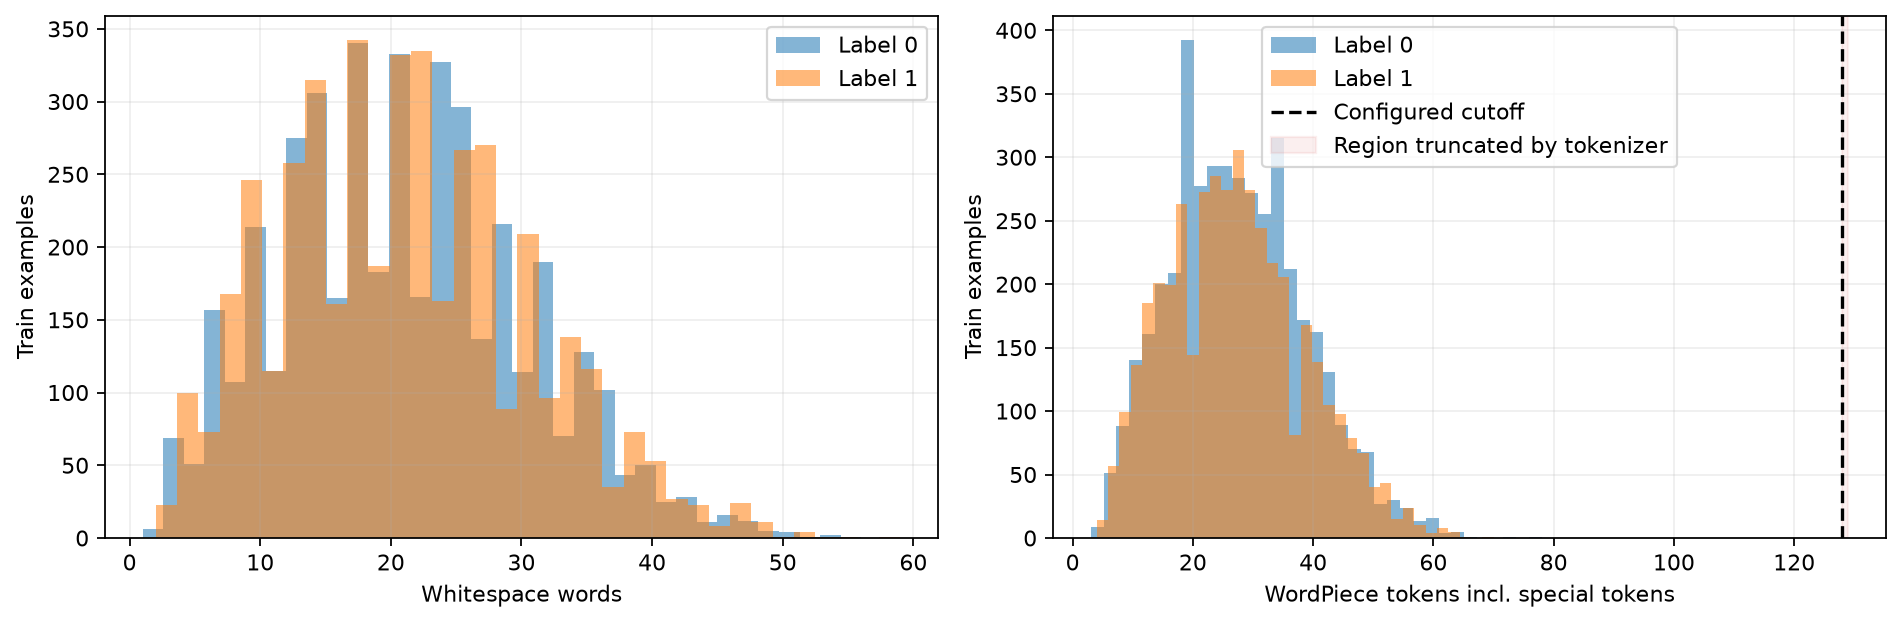

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/lengths_boxplot.png'),
 WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/lengths_by_class.png')]

In [5]:
session.show("data", ["lengths_boxplot.png", "lengths_by_class.png"])

## 6. Bước 5: Kiểm tra dữ liệu khuyết, trùng lặp & Rò rỉ dữ liệu (Data Leakage Audit)

Báo cáo rò rỉ dữ liệu chéo giữa các tập (Cross-split overlap):
  - train__validation: 0 mẫu trùng lặp văn bản
  - train__test: 0 mẫu trùng lặp văn bản
  - validation__test: 0 mẫu trùng lặp văn bản


**data_quality.png**

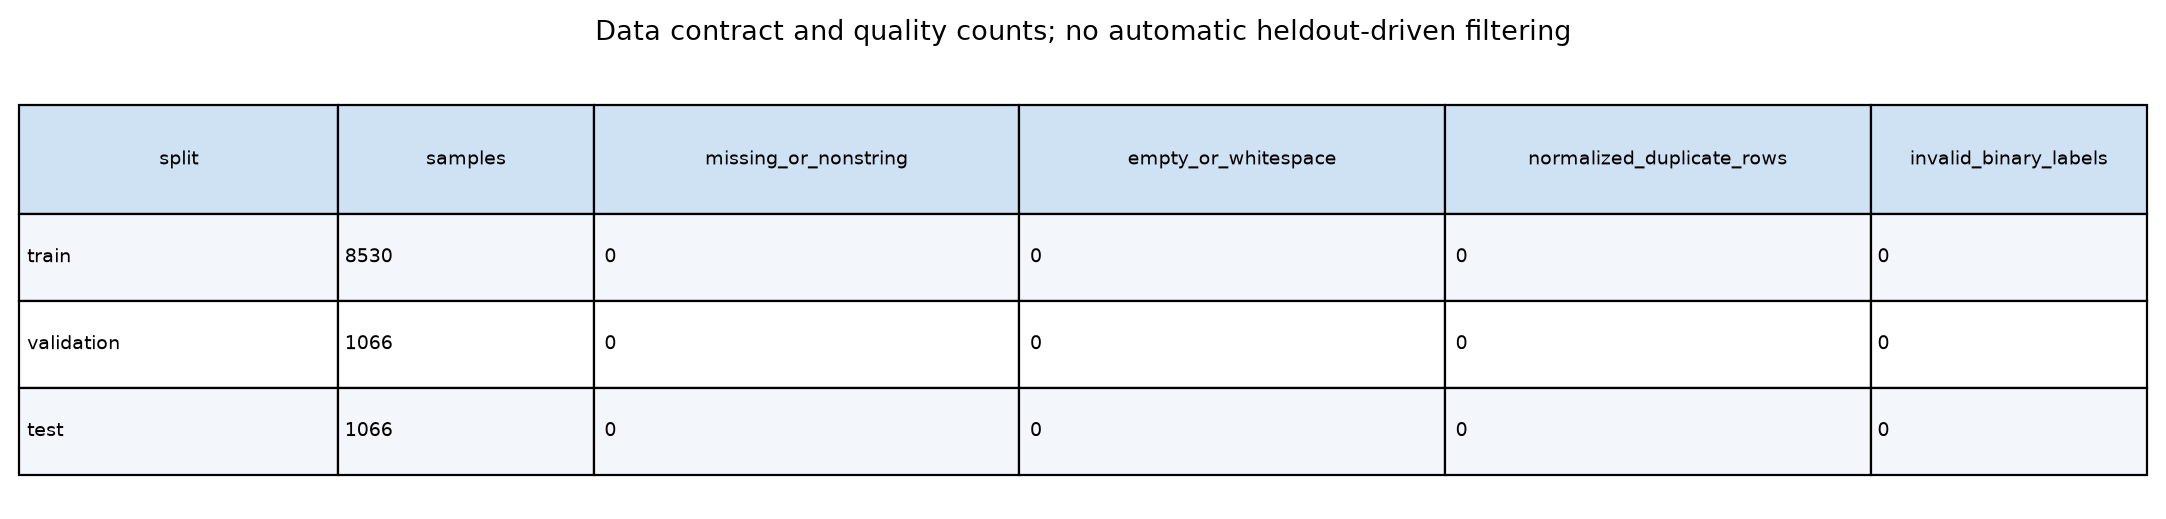

[WindowsPath('C:/Users/Win 11/Documents/Lab DL/labs/lab03/outputs/runs/20261103T110437Z_frozen_trial_b021d6eb/data_quality.png')]

In [6]:
quality = session.read(session.paths["data"] / "data_quality.json")
print("Báo cáo rò rỉ dữ liệu chéo giữa các tập (Cross-split overlap):")
for split_pair, overlap_count in quality.get("normalized_cross_split_overlap", {}).items():
    print(f"  - {split_pair}: {overlap_count} mẫu trùng lặp văn bản")

session.show("data", ["data_quality.png"])

## 7. Bước 6: Đánh giá chất lượng dữ liệu & Handoff sang Feature Engineering

In [7]:
print("Toàn bộ 6 bước EDA theo docs/eda.md đã được kiểm chứng đầy đủ.")
print("Đường dẫn lưu trữ artifact EDA:", session.paths["data"])

Toàn bộ 6 bước EDA theo docs/eda.md đã được kiểm chứng đầy đủ.
Đường dẫn lưu trữ artifact EDA: C:\Users\Win 11\Documents\Lab DL\labs\lab03\outputs\runs\20261103T110437Z_frozen_trial_b021d6eb
